In [1]:
# This mounts your Google Drive to the Colab VM.
from google.colab import drive
drive.mount('/content/drive')

# assignment folder, e.g. 'icv83551/assignments/assignment1/'
FOLDERNAME = 'icv83551/assignments/assignment1/'
assert FOLDERNAME is not None, "[!] Enter the foldername."

# Now that we've mounted your Drive, this ensures that
# the Python interpreter of the Colab VM can load
# python files from within it.
import sys
sys.path.append('/content/drive/My Drive/{}'.format(FOLDERNAME))

# This downloads the CIFAR-10 dataset to your Drive
# if it doesn't already exist.
%cd /content/drive/My\ Drive/$FOLDERNAME/icv83551/datasets/
!bash get_datasets.sh
%cd /content/drive/My\ Drive/$FOLDERNAME

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/My Drive/icv83551/assignments/assignment1/icv83551/datasets
/content/drive/My Drive/icv83551/assignments/assignment1


# Softmax Classifier exercise

*Complete and hand in this completed worksheet (including its outputs and any supporting code outside of the worksheet) with your assignment submission.

In this exercise you will:
    
- Implement a fully-vectorized **loss function** for the Softmax classifier.
- Implement the fully-vectorized expression for its **analytic gradient**
- **Check your implementation** using numerical gradient
- Use a validation set to **tune the learning rate and regularization** strength
- **Optimize** the loss function with **SGD**
- **Visualize** the final learned weights


In [2]:
# Run some setup code for this notebook.
import random
import numpy as np
from icv83551.data_utils import load_CIFAR10
import matplotlib.pyplot as plt

# This is a bit of magic to make matplotlib figures appear inline in the
# notebook rather than in a new window.
%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

#%load_ext autoreload
#%autoreload 2

## CIFAR-10 Data Loading and Preprocessing

In [3]:
# Load the raw CIFAR-10 data.
cifar10_dir = 'icv83551/datasets/cifar-10-batches-py'

# Cleaning up variables to prevent loading data multiple times (which may cause memory issue)
try:
   del X_train, y_train
   del X_test, y_test
   print('Clear previously loaded data.')
except:
   pass

X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

# As a sanity check, we print out the size of the training and test data.
print('Training data shape: ', X_train.shape)
print('Training labels shape: ', y_train.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Training data shape:  (50000, 32, 32, 3)
Training labels shape:  (50000,)
Test data shape:  (10000, 32, 32, 3)
Test labels shape:  (10000,)


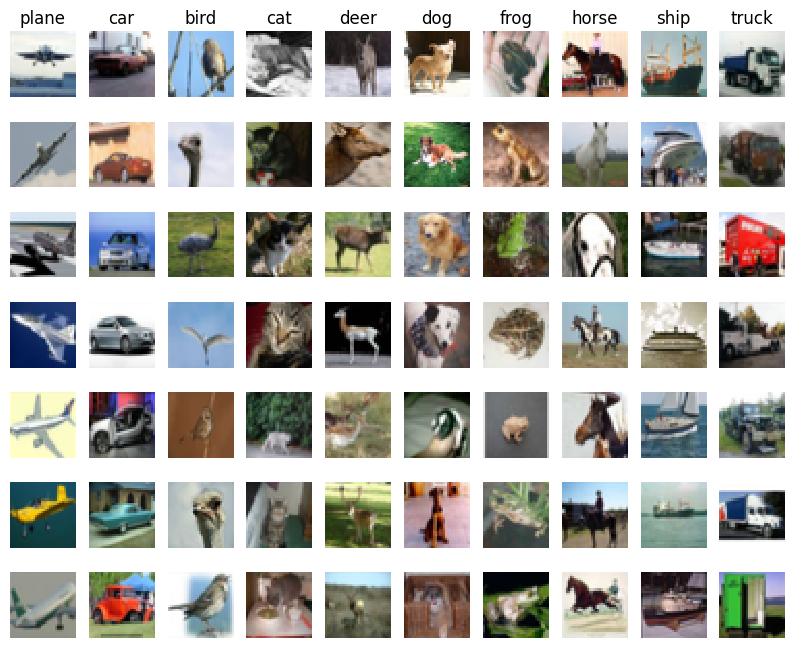

In [4]:
# Visualize some examples from the dataset.
# We show a few examples of training images from each class.
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
num_classes = len(classes)
samples_per_class = 7
for y, cls in enumerate(classes):
    idxs = np.flatnonzero(y_train == y)
    idxs = np.random.choice(idxs, samples_per_class, replace=False)
    for i, idx in enumerate(idxs):
        plt_idx = i * num_classes + y + 1
        plt.subplot(samples_per_class, num_classes, plt_idx)
        plt.imshow(X_train[idx].astype('uint8'))
        plt.axis('off')
        if i == 0:
            plt.title(cls)
plt.show()

In [5]:
# Split the data into train, val, and test sets. In addition we will
# create a small development set as a subset of the training data;
# we can use this for development so our code runs faster.
num_training = 49000
num_validation = 1000
num_test = 1000
num_dev = 500

# Our validation set will be num_validation points from the original
# training set.
mask = range(num_training, num_training + num_validation)
X_val = X_train[mask]
y_val = y_train[mask]

# Our training set will be the first num_train points from the original
# training set.
mask = range(num_training)
X_train = X_train[mask]
y_train = y_train[mask]

# We will also make a development set, which is a small subset of
# the training set.
mask = np.random.choice(num_training, num_dev, replace=False)
X_dev = X_train[mask]
y_dev = y_train[mask]

# We use the first num_test points of the original test set as our
# test set.
mask = range(num_test)
X_test = X_test[mask]
y_test = y_test[mask]

print('Train data shape: ', X_train.shape)
print('Train labels shape: ', y_train.shape)
print('Validation data shape: ', X_val.shape)
print('Validation labels shape: ', y_val.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Train data shape:  (49000, 32, 32, 3)
Train labels shape:  (49000,)
Validation data shape:  (1000, 32, 32, 3)
Validation labels shape:  (1000,)
Test data shape:  (1000, 32, 32, 3)
Test labels shape:  (1000,)


In [6]:
# Preprocessing: reshape the image data into rows
X_train = np.reshape(X_train, (X_train.shape[0], -1))
X_val = np.reshape(X_val, (X_val.shape[0], -1))
X_test = np.reshape(X_test, (X_test.shape[0], -1))
X_dev = np.reshape(X_dev, (X_dev.shape[0], -1))

# As a sanity check, print out the shapes of the data
print('Training data shape: ', X_train.shape)
print('Validation data shape: ', X_val.shape)
print('Test data shape: ', X_test.shape)
print('dev data shape: ', X_dev.shape)

Training data shape:  (49000, 3072)
Validation data shape:  (1000, 3072)
Test data shape:  (1000, 3072)
dev data shape:  (500, 3072)


[130.64189796 135.98173469 132.47391837 130.05569388 135.34804082
 131.75402041 130.96055102 136.14328571 132.47636735 131.48467347]


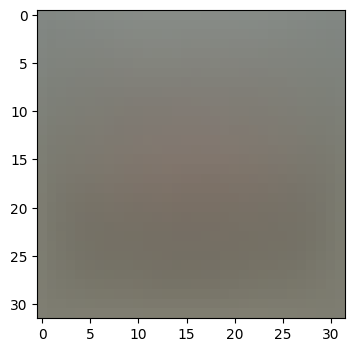

(49000, 3073) (1000, 3073) (1000, 3073) (500, 3073)


In [7]:
# Preprocessing: subtract the mean image
# first: compute the image mean based on the training data
mean_image = np.mean(X_train, axis=0)
print(mean_image[:10]) # print a few of the elements
plt.figure(figsize=(4,4))
plt.imshow(mean_image.reshape((32,32,3)).astype('uint8')) # visualize the mean image
plt.show()

# second: subtract the mean image from train and test data
X_train -= mean_image
X_val -= mean_image
X_test -= mean_image
X_dev -= mean_image

# third: append the bias dimension of ones (i.e. bias trick) so that our classifier
# only has to worry about optimizing a single weight matrix W.
X_train = np.hstack([X_train, np.ones((X_train.shape[0], 1))])
X_val = np.hstack([X_val, np.ones((X_val.shape[0], 1))])
X_test = np.hstack([X_test, np.ones((X_test.shape[0], 1))])
X_dev = np.hstack([X_dev, np.ones((X_dev.shape[0], 1))])

print(X_train.shape, X_val.shape, X_test.shape, X_dev.shape)

## Softmax Classifier

Your code for this section will all be written inside `icv83551/classifiers/softmax.py`.

As you can see, we have prefilled the function `softmax_loss_naive` which uses for loops to evaluate the softmax loss function.

In [8]:
# Evaluate the naive implementation of the loss we provided for you:
from icv83551.classifiers.softmax import softmax_loss_naive
import time

# generate a random Softmax classifier weight matrix of small numbers
W = np.random.randn(3073, 10) * 0.0001

loss, grad = softmax_loss_naive(W, X_dev, y_dev, 0.000005)
print('loss: %f' % (loss, ))

# As a rough sanity check, our loss should be something close to -log(0.1).
print('loss: %f' % loss)
print('sanity check: %f' % (-np.log(0.1)))

loss: 2.370051
loss: 2.370051
sanity check: 2.302585


**Inline Question 1**

Why do we expect our loss to be close to -log(0.1)? Explain briefly.


**Answer:**

Since the weights are initialized with small random values,
the classifier initially produces approximately equal scores
for all 10 classes.

Therefore, the Softmax probabilities are approximately
uniform, assigning a probability of 0.1 to each class.

Since the cross-entropy loss is the negative logarithm of
the probability assigned to the correct class, we expect:

L = -log(0.1) = log(10) ≈ 2.302585.

Small deviations may occur due to random initialization
and regularization.




The `grad` returned from the function above is right now all zero. Derive and implement the gradient for the softmax loss function and implement it inline inside the function `softmax_loss_naive`. You will find it helpful to interleave your new code inside the existing function.

To check that you have correctly implemented the gradient, you can numerically estimate the gradient of the loss function and compare the numeric estimate to the gradient that you computed. We have provided code that does this for you:

In [9]:
# Once you've implemented the gradient, recompute it with the code below
# and gradient check it with the function we provided for you

# Compute the loss and its gradient at W.
loss, grad = softmax_loss_naive(W, X_dev, y_dev, 0.0)

# Numerically compute the gradient along several randomly chosen dimensions, and
# compare them with your analytically computed gradient. The numbers should match
# almost exactly along all dimensions.
from icv83551.gradient_check import grad_check_sparse
f = lambda w: softmax_loss_naive(w, X_dev, y_dev, 0.0)[0]
grad_numerical = grad_check_sparse(f, W, grad)

# do the gradient check once again with regularization turned on
# you didn't forget the regularization gradient did you?
loss, grad = softmax_loss_naive(W, X_dev, y_dev, 5e1)
f = lambda w: softmax_loss_naive(w, X_dev, y_dev, 5e1)[0]
grad_numerical = grad_check_sparse(f, W, grad)

numerical: -1.735637 analytic: -1.735637, relative error: 2.262308e-09
numerical: -3.398134 analytic: -3.398134, relative error: 8.202292e-09
numerical: 1.754937 analytic: 1.754938, relative error: 4.701816e-09
numerical: -0.809591 analytic: -0.809591, relative error: 2.402182e-08
numerical: 0.606612 analytic: 0.606611, relative error: 1.017210e-07
numerical: 0.564246 analytic: 0.564246, relative error: 5.532337e-08
numerical: 0.506620 analytic: 0.506620, relative error: 1.612561e-07
numerical: 1.147228 analytic: 1.147228, relative error: 4.187157e-08
numerical: 0.647844 analytic: 0.647844, relative error: 3.666609e-08
numerical: -2.518258 analytic: -2.518258, relative error: 1.642718e-08
numerical: -1.068053 analytic: -1.068053, relative error: 4.667622e-08
numerical: -0.599801 analytic: -0.599801, relative error: 1.069321e-08
numerical: 0.800668 analytic: 0.800668, relative error: 1.186702e-07
numerical: -0.925018 analytic: -0.925018, relative error: 3.272391e-08
numerical: -0.446022

**Inline Question 2**

Although gradcheck is reliable softmax loss, it is possible that for SVM loss, once in a while, a dimension in the gradcheck will not match exactly. What could such a discrepancy be caused by? Is it a reason for concern? What is a simple example in one dimension where a svm loss gradient check could fail? How would change the margin affect of the frequency of this happening?

Note that SVM loss for a sample $(x_i, y_i)$ is defined as: $$L_i = \sum_{j\ne y_i}\max(0, s_j - s_{y_i} + \Delta)$$ Where $j$ iterates over all classes except the correct class $y_i$ and $s_j$ denotes the classifier score for $j^{th}$ class. $\Delta$ is a scalar margin.
*Hint: the SVM loss function is not strictly speaking differentiable.*



**Answer:**

The discrepancy may occur because the SVM hinge loss is not differentiable at points where the margin constraint is exactly satisfied, i.e., when

$s_j - s_{y_i} + \Delta = 0$.

Near such points, a numerical gradient check may cross the non-differentiable boundary and produce a value different from the analytical gradient.

This is not necessarily a reason for concern, as occasional discrepancies near these points are expected.

For example, consider the one-dimensional function

$f(w) = \max(0, w+1)$.

At $w=-1$, the function is not differentiable. The centered numerical gradient gives $0.5$, while the analytical implementation may use a subgradient of $0$ or $1$.

Changing the margin $\Delta$ shifts the location of these non-differentiable boundaries. The frequency of discrepancies depends on the distribution of the scores. For scores concentrated near zero, decreasing the margin toward zero may increase the frequency of such discrepancies.



In [10]:
# Next implement the function softmax_loss_vectorized; for now only compute the loss;
# we will implement the gradient in a moment.
tic = time.time()
loss_naive, grad_naive = softmax_loss_naive(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Naive loss: %e computed in %fs' % (loss_naive, toc - tic))

from icv83551.classifiers.softmax import softmax_loss_vectorized
tic = time.time()
loss_vectorized, _ = softmax_loss_vectorized(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Vectorized loss: %e computed in %fs' % (loss_vectorized, toc - tic))

# The losses should match but your vectorized implementation should be much faster.
print('difference: %f' % (loss_naive - loss_vectorized))

Naive loss: 2.370051e+00 computed in 0.061791s
Vectorized loss: 2.370051e+00 computed in 0.012485s
difference: -0.000000


In [11]:
# Complete the implementation of softmax_loss_vectorized, and compute the gradient
# of the loss function in a vectorized way.

# The naive implementation and the vectorized implementation should match, but
# the vectorized version should still be much faster.
tic = time.time()
_, grad_naive = softmax_loss_naive(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Naive loss and gradient: computed in %fs' % (toc - tic))

tic = time.time()
_, grad_vectorized = softmax_loss_vectorized(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Vectorized loss and gradient: computed in %fs' % (toc - tic))

# The loss is a single number, so it is easy to compare the values computed
# by the two implementations. The gradient on the other hand is a matrix, so
# we use the Frobenius norm to compare them.
difference = np.linalg.norm(grad_naive - grad_vectorized, ord='fro')
print('difference: %f' % difference)

Naive loss and gradient: computed in 0.089092s
Vectorized loss and gradient: computed in 0.011167s
difference: 0.000000


### Stochastic Gradient Descent

We now have vectorized and efficient expressions for the loss, the gradient and our gradient matches the numerical gradient. We are therefore ready to do SGD to minimize the loss. Your code for this part will be written inside `icv83551/classifiers/linear_classifier.py`.

In [15]:
# In the file linear_classifier.py, implement SGD in the function
# LinearClassifier.train() and then run it with the code below.
import importlib
import icv83551.classifiers.linear_classifier as linear_module

importlib.reload(linear_module)
Softmax = linear_module.Softmax

softmax = Softmax()
tic = time.time()
loss_hist = softmax.train(X_train, y_train, learning_rate=1e-7, reg=2.5e4,
                      num_iters=1500, verbose=True)
toc = time.time()
print('That took %fs' % (toc - tic))

iteration 0 / 1500: loss 763.123451
iteration 100 / 1500: loss 280.046847
iteration 200 / 1500: loss 103.701300
iteration 300 / 1500: loss 39.231133
iteration 400 / 1500: loss 15.718772
iteration 500 / 1500: loss 7.069307
iteration 600 / 1500: loss 3.922389
iteration 700 / 1500: loss 2.740163
iteration 800 / 1500: loss 2.303055
iteration 900 / 1500: loss 2.137157
iteration 1000 / 1500: loss 2.139514
iteration 1100 / 1500: loss 2.077574
iteration 1200 / 1500: loss 2.079028
iteration 1300 / 1500: loss 2.094810
iteration 1400 / 1500: loss 2.146529
That took 12.711854s


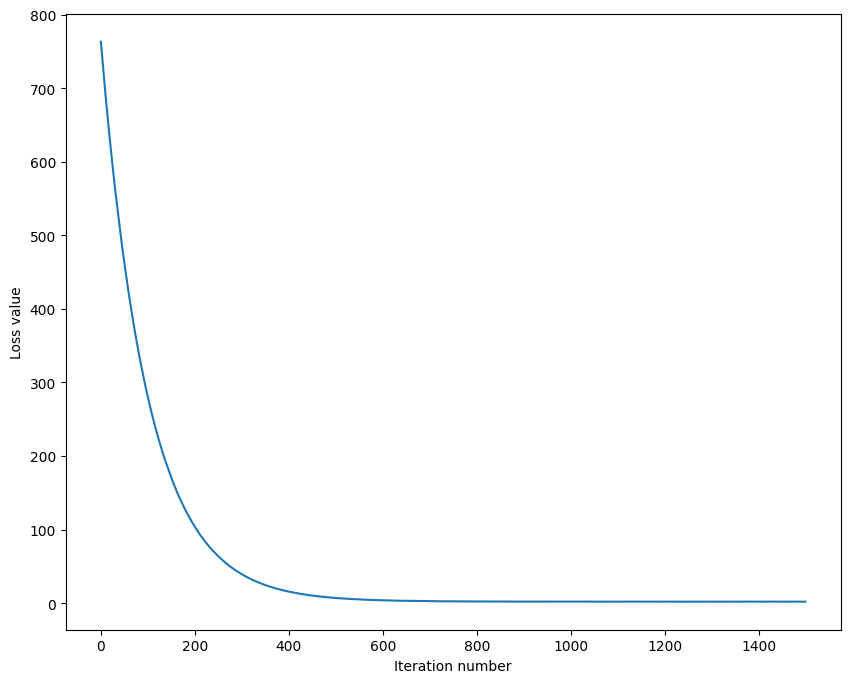

In [16]:
# A useful debugging strategy is to plot the loss as a function of
# iteration number:
plt.plot(loss_hist)
plt.xlabel('Iteration number')
plt.ylabel('Loss value')
plt.show()

In [17]:
# Write the LinearClassifier.predict function and evaluate the performance on
# both the training and validation set
# You should get validation accuracy of about 0.34 (> 0.33).
y_train_pred = softmax.predict(X_train)
print('training accuracy: %f' % (np.mean(y_train == y_train_pred), ))
y_val_pred = softmax.predict(X_val)
print('validation accuracy: %f' % (np.mean(y_val == y_val_pred), ))

training accuracy: 0.333204
validation accuracy: 0.345000


In [18]:
# Save the trained model for autograder.
softmax.save("softmax.npy")

softmax.npy saved.


In [21]:
# Use the validation set to tune hyperparameters (regularization strength and
# learning rate). You should experiment with different ranges for the learning
# rates and regularization strengths; if you are careful you should be able to
# get a classification accuracy of about 0.365 (> 0.36) on the validation set.

# Note: you may see runtime/overflow warnings during hyper-parameter search.
# This may be caused by extreme values, and is not a bug.

# results is dictionary mapping tuples of the form
# (learning_rate, regularization_strength) to tuples of the form
# (training_accuracy, validation_accuracy). The accuracy is simply the fraction
# of data points that are correctly classified.
results = {}
best_val = -1   # The highest validation accuracy that we have seen so far.
best_softmax = None # The Softmax object that achieved the highest validation rate.


# Provided as a reference. You may or may not want to change these hyperparameters
learning_rates = [1e-7, 2e-7, 5e-7]
regularization_strengths = [1e3, 1e4, 2.5e4]


# Make sure we use the updated classifier implementation
import importlib
import icv83551.classifiers.linear_classifier as linear_module

importlib.reload(linear_module)
Softmax = linear_module.Softmax

# Search for the best hyperparameters
for lr in learning_rates:
    for reg in regularization_strengths:

        # Create a new Softmax classifier
        model = Softmax()

        # Train the classifier
        model.train(
            X_train,
            y_train,
            learning_rate=lr,
            reg=reg,
            num_iters=1500,
            batch_size=200,
            verbose=False
        )

        # Compute training accuracy
        y_train_pred = model.predict(X_train)
        train_accuracy = np.mean(y_train_pred == y_train)

        # Compute validation accuracy
        y_val_pred = model.predict(X_val)
        val_accuracy = np.mean(y_val_pred == y_val)

        # Store the results
        results[(lr, reg)] = (train_accuracy, val_accuracy)

        # Update the best classifier
        if val_accuracy > best_val:
            best_val = val_accuracy
            best_softmax = model


# Print out results.
for lr, reg in sorted(results):
    train_accuracy, val_accuracy = results[(lr, reg)]
    print('lr %e reg %e train accuracy: %f val accuracy: %f' % (
                lr, reg, train_accuracy, val_accuracy))

print('best validation accuracy achieved during cross-validation: %f' % best_val)

lr 1.000000e-07 reg 1.000000e+03 train accuracy: 0.265469 val accuracy: 0.260000
lr 1.000000e-07 reg 1.000000e+04 train accuracy: 0.354388 val accuracy: 0.371000
lr 1.000000e-07 reg 2.500000e+04 train accuracy: 0.326673 val accuracy: 0.338000
lr 2.000000e-07 reg 1.000000e+03 train accuracy: 0.313000 val accuracy: 0.313000
lr 2.000000e-07 reg 1.000000e+04 train accuracy: 0.357306 val accuracy: 0.372000
lr 2.000000e-07 reg 2.500000e+04 train accuracy: 0.333837 val accuracy: 0.347000
lr 5.000000e-07 reg 1.000000e+03 train accuracy: 0.387776 val accuracy: 0.395000
lr 5.000000e-07 reg 1.000000e+04 train accuracy: 0.353163 val accuracy: 0.367000
lr 5.000000e-07 reg 2.500000e+04 train accuracy: 0.322918 val accuracy: 0.337000
best validation accuracy achieved during cross-validation: 0.395000


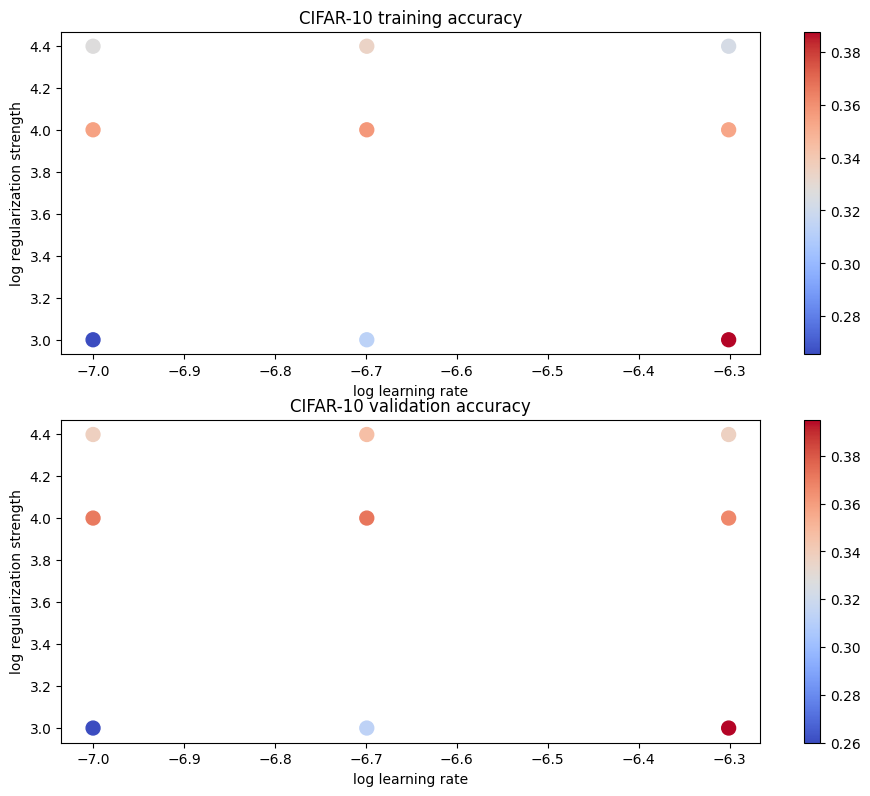

In [22]:
# Visualize the cross-validation results
import math
import pdb

# pdb.set_trace()

x_scatter = [math.log10(x[0]) for x in results]
y_scatter = [math.log10(x[1]) for x in results]

# plot training accuracy
marker_size = 100
colors = [results[x][0] for x in results]
plt.subplot(2, 1, 1)
plt.tight_layout(pad=3)
plt.scatter(x_scatter, y_scatter, marker_size, c=colors, cmap=plt.cm.coolwarm)
plt.colorbar()
plt.xlabel('log learning rate')
plt.ylabel('log regularization strength')
plt.title('CIFAR-10 training accuracy')

# plot validation accuracy
colors = [results[x][1] for x in results] # default size of markers is 20
plt.subplot(2, 1, 2)
plt.scatter(x_scatter, y_scatter, marker_size, c=colors, cmap=plt.cm.coolwarm)
plt.colorbar()
plt.xlabel('log learning rate')
plt.ylabel('log regularization strength')
plt.title('CIFAR-10 validation accuracy')
plt.show()

In [23]:
# Evaluate the best softmax on test set
y_test_pred = best_softmax.predict(X_test)
test_accuracy = np.mean(y_test == y_test_pred)
print('Softmax classifier on raw pixels final test set accuracy: %f' % test_accuracy)

Softmax classifier on raw pixels final test set accuracy: 0.373000


In [24]:
# Save best softmax model
best_softmax.save("best_softmax.npy")

best_softmax.npy saved.


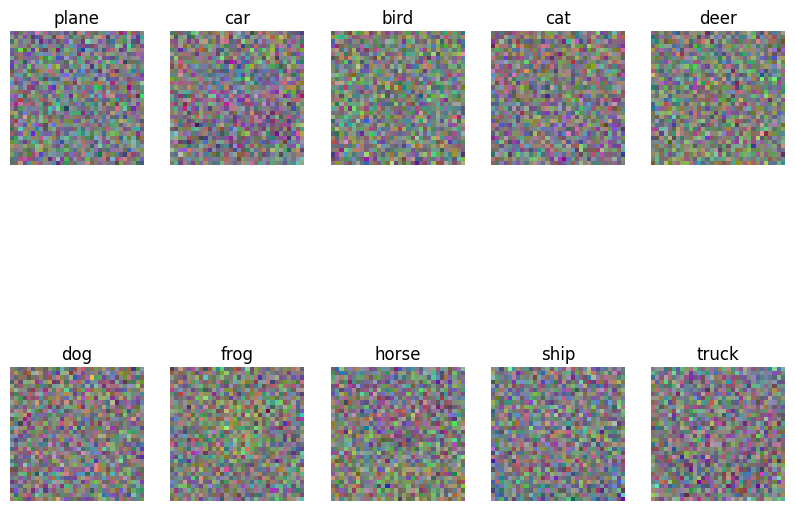

In [25]:
# Visualize the learned weights for each class.
# Depending on your choice of learning rate and regularization strength, these may
# or may not be nice to look at.
w = best_softmax.W[:-1,:] # strip out the bias
w = w.reshape(32, 32, 3, 10)
w_min, w_max = np.min(w), np.max(w)
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Rescale the weights to be between 0 and 255
    wimg = 255.0 * (w[:, :, :, i].squeeze() - w_min) / (w_max - w_min)
    plt.imshow(wimg.astype('uint8'))
    plt.axis('off')
    plt.title(classes[i])

**Inline question 3**

Describe what your visualized Softmax classifier weights look like, and offer a brief explanation for why they look the way they do.


**Answer:**

The visualized Softmax weights appear mostly noisy and colorful, without clearly recognizable objects. Some weak class-specific color and spatial patterns may be visible.

This is because the Softmax classifier is a linear model that learns a weight for each pixel and class. It operates directly on raw pixel values and cannot learn complex spatial features or object shapes.

Therefore, the weights mainly capture low-level color and pixel patterns rather than clear representations of the objects.


**Inline Question 4** - *True or False*

Suppose the overall training loss is defined as the sum of the per-datapoint loss over all training examples. It is possible to add a new datapoint to a training set that would change the softmax loss, but leave the SVM loss unchanged.


**Answer:** True.

**Explanation:**

The SVM hinge loss becomes zero when the correct class score exceeds all incorrect class scores by at least the margin. Therefore, adding a new training example that satisfies this condition does not change the total SVM loss.

However, the Softmax cross-entropy loss is strictly positive for finite scores, since the probability assigned to the correct class is less than 1.

For example, with two classes, a margin of 1, and scores of 2 for the correct class and 0 for the incorrect class, the SVM loss is zero, while the Softmax loss is approximately 0.127.

Thus, adding this example changes the total Softmax loss but leaves the total SVM loss unchanged.
